In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np

import torch
from torch.utils.data import Dataset, DataLoader


from transformers import (
  TrainingArguments, 
  Trainer, 
  EarlyStoppingCallback, 
  PatchTSTConfig, 
  PatchTSTForPrediction
)


%load_ext tensorboard

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [4]:
# Check PyTorch version and the CUDA version it was compiled with
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA version used by PyTorch: {torch.version.cuda}")

# Check if CUDA is available for PyTorch to use
is_available = torch.cuda.is_available()
print(f"Is CUDA available? {is_available}")

if is_available:
    # Get the number of available GPUs
    print(f"Number of GPUs: {torch.cuda.device_count()}")
    # Get the name of the primary GPU
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    
    
else:
    print("CUDA is not available. PyTorch is running on CPU.")


device = device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


PyTorch version: 2.9.0+cu130
CUDA version used by PyTorch: 13.0
Is CUDA available? True
Number of GPUs: 1
GPU Name: NVIDIA GeForce RTX 3060 Laptop GPU
Using device: cuda:0


In [5]:
df = pd.read_csv('data/SBER_1H_filled_with_features.csv',
                 parse_dates=['timestamp'], index_col='timestamp')
df.sort_index(inplace=True)

df.columns

Index(['open', 'high', 'low', 'close', 'volume', 'value', 'mask_original',
       'log_open', 'log_high', 'log_low', 'log_close', 'ret1', 'ret_open',
       'ret_high', 'ret_low', 'ret_co', 'ret_hl', 'range', 'body',
       'upper_wick', 'lower_wick', 'body_pct', 'upper_wick_pct',
       'lower_wick_pct', 'typical_price', 'dow', 'hour'],
      dtype='object')

In [6]:
df.head()

,open,high,low,close,volume,value,mask_original,log_open,log_high,log_low,...,range,body,upper_wick,lower_wick,body_pct,upper_wick_pct,lower_wick_pct,typical_price,dow,hour
timestamp,,,,,,,,,,,,,,,,,,,,,
2011-12-15 10:00:00,79.90,80.40,79.39,79.86,43586210.0,3.484414e+09,True,4.380776,4.387014,4.374372,...,1.01,-0.04,0.50,0.47,-0.039604,0.495050,0.465347,79.883333,3,10
2011-12-15 11:00:00,79.86,81.05,79.84,80.80,27993640.0,2.247438e+09,True,4.380275,4.395066,4.380025,...,1.21,0.94,0.25,0.02,0.776860,0.206612,0.016529,80.563333,3,11
2011-12-15 12:00:00,80.80,81.41,80.37,80.88,29467050.0,2.384109e+09,True,4.391977,4.399498,4.386641,...,1.04,0.08,0.53,0.43,0.076923,0.509615,0.413462,80.886667,3,12
2011-12-15 13:00:00,80.88,81.00,79.76,80.06,24692240.0,1.983179e+09,True,4.392967,4.394449,4.379022,...,1.24,-0.82,0.12,0.30,-0.661290,0.096774,0.241935,80.273333,3,13
2011-12-15 14:00:00,80.06,81.10,79.86,80.90,25133560.0,2.022180e+09,True,4.382776,4.395683,4.380275,...,1.24,0.84,0.20,0.20,0.677419,0.161290,0.161290,80.620000,3,14


In [7]:
# target = 'ret1'
mask_original = 'mask_original'
features = df.columns.drop([mask_original])

feature_data = df[features].astype('float32').values
# target_data = df[target].astype('float32').values
mask_data = df[mask_original].values


num_input_features = feature_data.shape[1]
# num_target_features = target_data.shape[1] if len(target_data.shape) > 1 else 1


seq_len = 24
pred_len = 1


num_input_features, feature_data.shape

(26, (120918, 26))

In [8]:
mean = feature_data.mean(axis=0)
std = feature_data.std(axis=0)

feature_data = (feature_data - mean) / std

In [9]:
num_train = int(len(df) * 0.7)
num_test = int(len(df) * 0.2)
num_val = len(df) - num_train - num_test

border1s = [
  0,
  num_train - seq_len,
  len(df) - num_test - seq_len
]

border2s = [
  num_train,
  num_train + num_val,
  len(df)
]

train_start_index = border1s[0]
train_end_index = border2s[0]

valid_start_index = border1s[1]
valid_end_index = border2s[1]

test_start_index = border1s[2]
test_end_index = border2s[2]


train_data = feature_data[train_start_index:train_end_index]
mask_train = mask_data[train_start_index:train_end_index]
# y_train = df[target].astype('float32').values[train_start_index:train_end_index]

validation_data = feature_data[valid_start_index:valid_end_index]
validation_mask = mask_data[valid_start_index:valid_end_index]
# y_val = df[target].astype('float32').values[valid_start_index:valid_end_index]

test_data = feature_data[test_start_index:test_end_index]
test_mask = mask_data[test_start_index:test_end_index]
# y_test = df[target].astype('float32').values[test_start_index:test_end_index]

In [10]:


class TimeSeriesForecastDataset(Dataset):
  def __init__(self, feature_data, past_observed_mask, seq_len, pred_len):
    self.feature_data = feature_data
    self.seq_len = seq_len
    self.pred_len = pred_len
    self.past_observed_mask = past_observed_mask

    # Общее количество выборок, которое можно сгенерировать
    self.num_samples = len(feature_data) - seq_len - pred_len + 1

  def __len__(self):
    """Возвращает общее количество выборок в датасете."""
    return self.num_samples

  def __getitem__(self, idx):
    """
    Возвращает одну выборку (признаки и цель) по индексу.
    Эта функция будет вызываться DataLoader'ом для каждого элемента в батче.
    """
    start_idx = idx
    end_seq_idx = start_idx + self.seq_len
    end_label_idx = end_seq_idx + self.pred_len

    # Извлекаем последовательность и метку
    sequence = self.feature_data[start_idx:end_seq_idx]
    past_mask = self.past_observed_mask[start_idx:end_seq_idx]
    label = self.feature_data[end_seq_idx:end_label_idx]
    future_mask = self.past_observed_mask[end_seq_idx:end_label_idx]
    

    # Преобразуем в тензоры PyTorch
    # PatchTST ожидает тензоры определенной формы
    # return torch.tensor(sequence, dtype=torch.float64), torch.tensor(label, dtype=torch.float64)
    return {
      'past_values': torch.tensor(sequence),
      'future_values': torch.tensor(label),
      'past_observed_mask': torch.tensor(past_mask, dtype=torch.bool).unsqueeze(1).expand(-1, num_input_features),
      'future_observed_mask': torch.tensor(future_mask, dtype=torch.bool)
    }
  
train_dataset = TimeSeriesForecastDataset(train_data, mask_train, seq_len, pred_len)
val_dataset = TimeSeriesForecastDataset(validation_data, validation_mask, seq_len, pred_len)

In [11]:

batch_size = 32

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True  # Перемешивание данных важно для качественного обучения
)

In [12]:


# Prapering config for training on data/SBER_1H_filled_with_features.csv dataset
config = PatchTSTConfig(
  num_input_channels=num_input_features, # input features
  num_targets=num_input_features,
  
  d_model=256, # num of hidden layers
  
  context_length=seq_len, # input sequence length
  prediction_length = pred_len, # output sequence length
  
  patch_length=12,
  patch_stride=1,
  loss='mse',
  
  scaling=None, # inner scaling of dataset: (input - mean) / std
  
  
)

# model = PatchTSTForPrediction(
#   config,
# )
model = PatchTSTForPrediction(config)
model

PatchTSTForPrediction(
  (model): PatchTSTModel(
    (scaler): PatchTSTScaler(
      (scaler): PatchTSTNOPScaler()
    )
    (patchifier): PatchTSTPatchify()
    (masking): Identity()
    (encoder): PatchTSTEncoder(
      (embedder): PatchTSTEmbedding(
        (input_embedding): Linear(in_features=12, out_features=256, bias=True)
      )
      (positional_encoder): PatchTSTPositionalEncoding(
        (positional_dropout): Identity()
      )
      (layers): ModuleList(
        (0-2): 3 x PatchTSTEncoderLayer(
          (self_attn): PatchTSTAttention(
            (k_proj): Linear(in_features=256, out_features=256, bias=True)
            (v_proj): Linear(in_features=256, out_features=256, bias=True)
            (q_proj): Linear(in_features=256, out_features=256, bias=True)
            (out_proj): Linear(in_features=256, out_features=256, bias=True)
          )
          (dropout_path1): Identity()
          (norm_sublayer1): PatchTSTBatchNorm(
            (batchnorm): BatchNorm1d(256, eps

In [13]:

training_args = TrainingArguments(
    output_dir='model',
    overwrite_output_dir=True,
    save_strategy='epoch',
    save_total_limit=3,

    num_train_epochs=100,

    do_eval=True,
    eval_strategy='epoch',

    per_device_eval_batch_size=batch_size,
    per_device_train_batch_size=batch_size,
    # dataloader_num_workers=num_workers,

    logging_strategy='epoch',
    logging_dir='logs',

    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,

    label_names=['future_values']
)

early_stopping_callback = EarlyStoppingCallback(
    # Number of epochs with no improvement after which to stop
    early_stopping_patience=10,
    # Minimum improvement required to consider as improvement
    early_stopping_threshold=0.0001,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    callbacks=[early_stopping_callback],
    
    # compute_metrics=compute_metrics,
)

training_args.device

device(type='cuda', index=0)

In [14]:
trainer.train()

Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

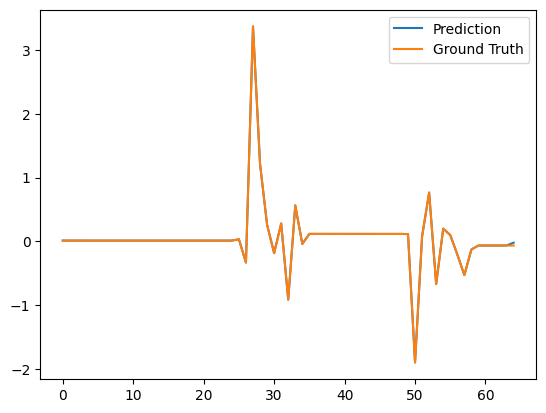

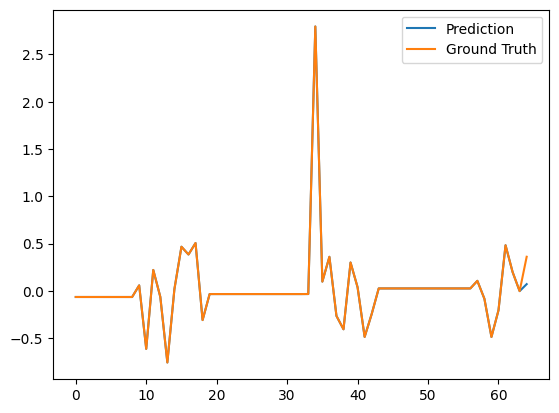

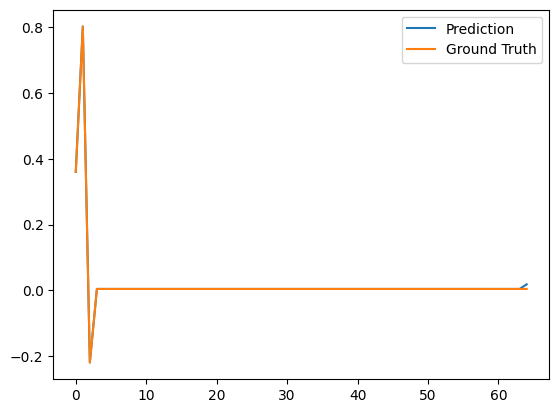

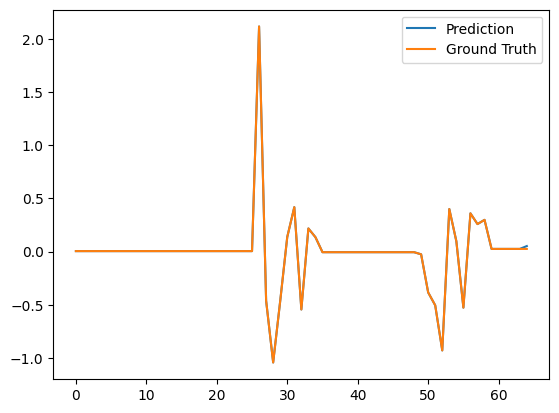

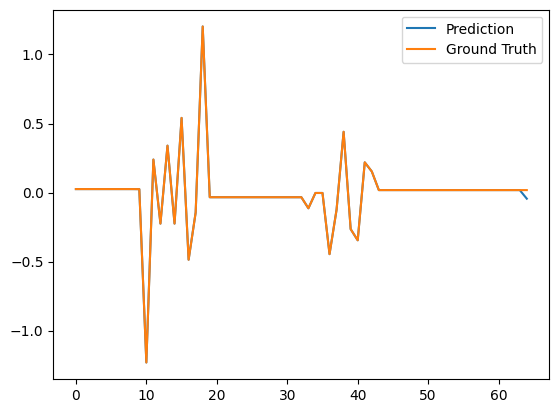

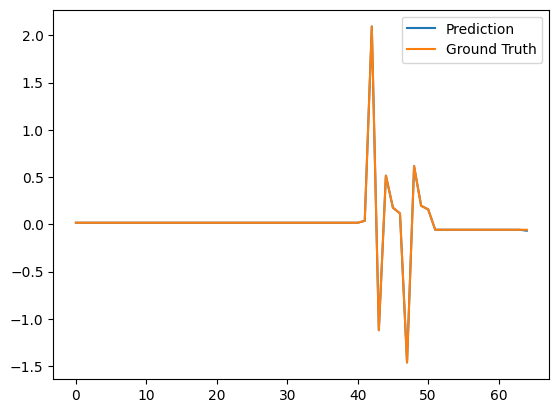

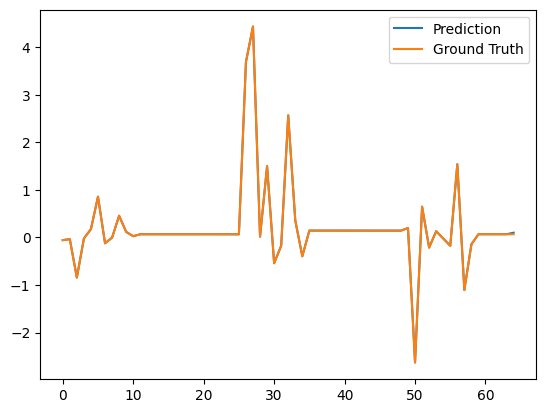

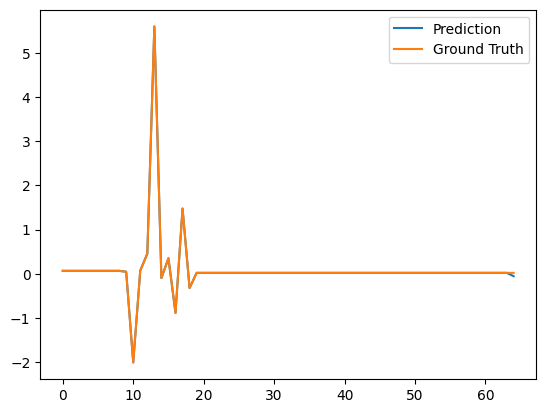

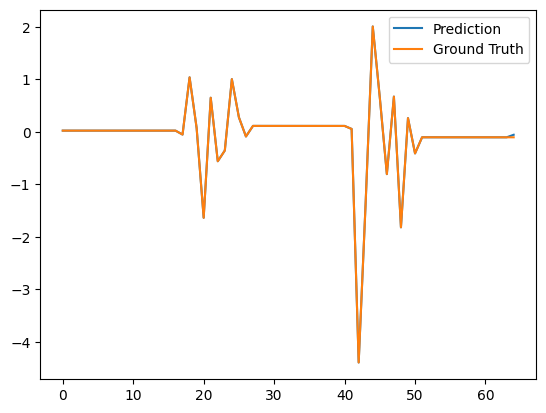

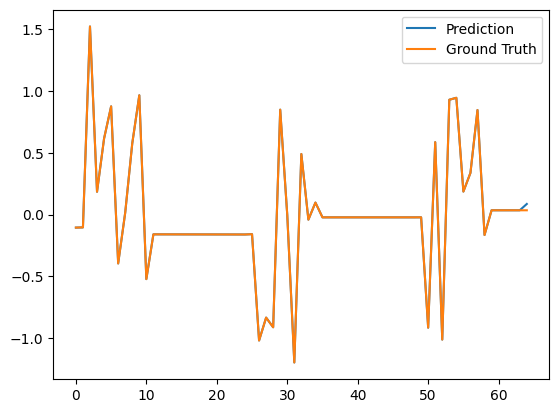

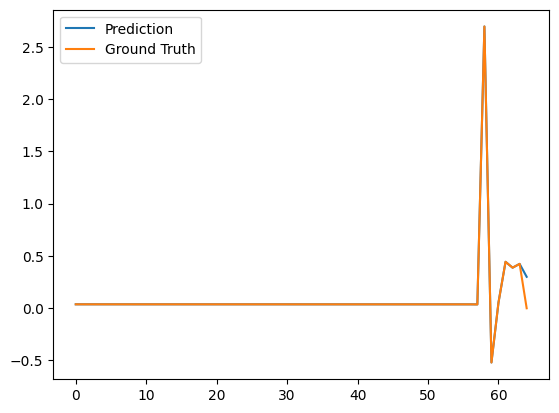

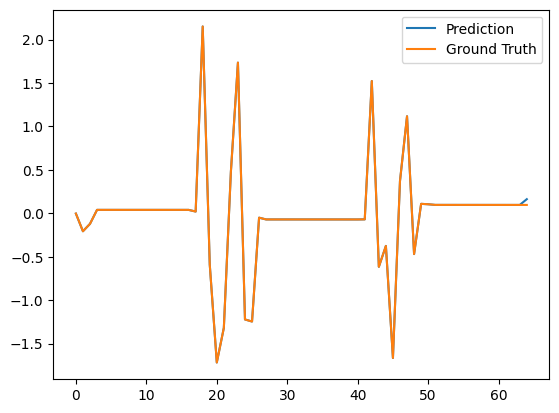

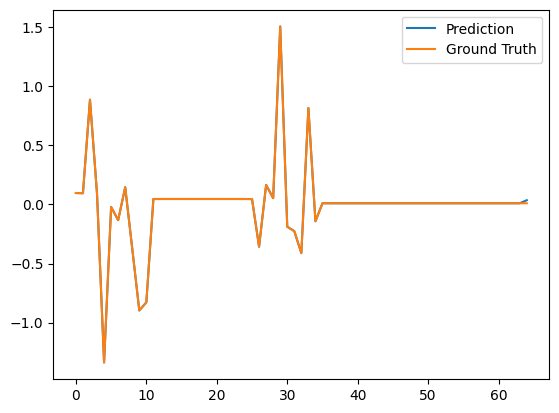

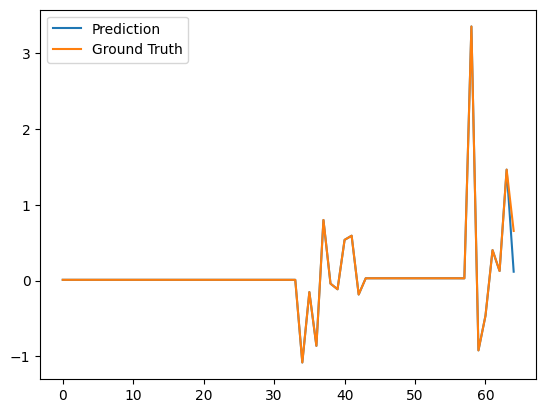

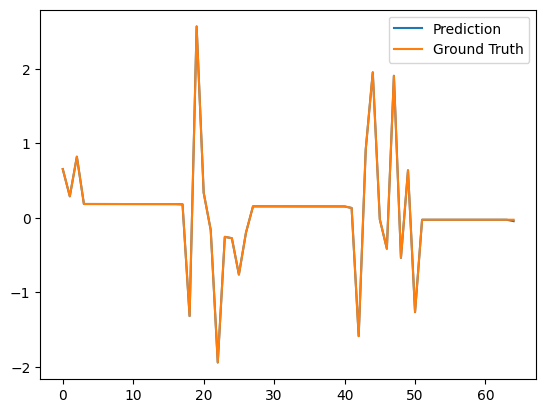

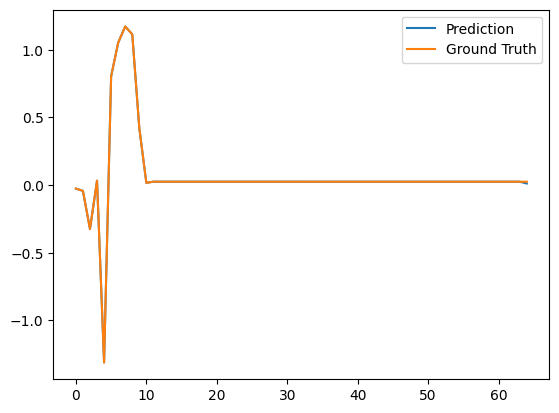

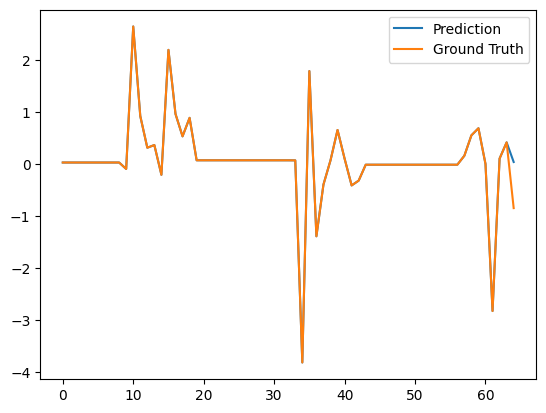

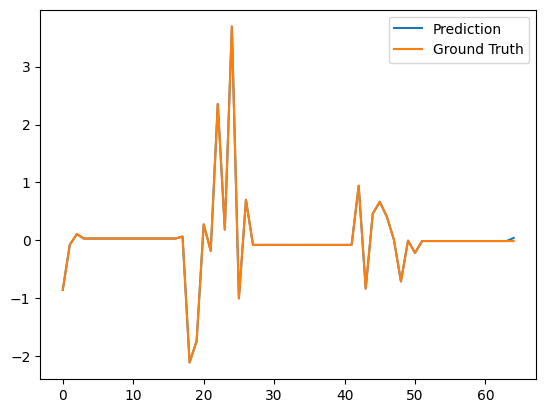

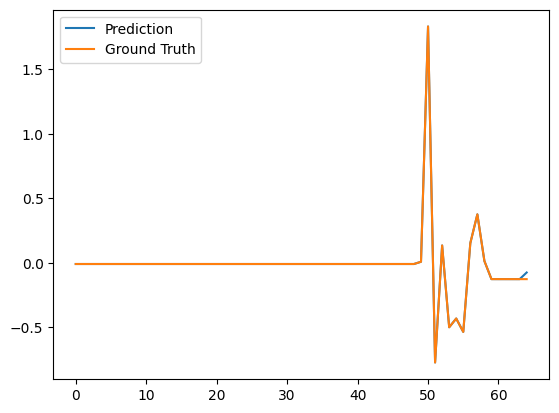

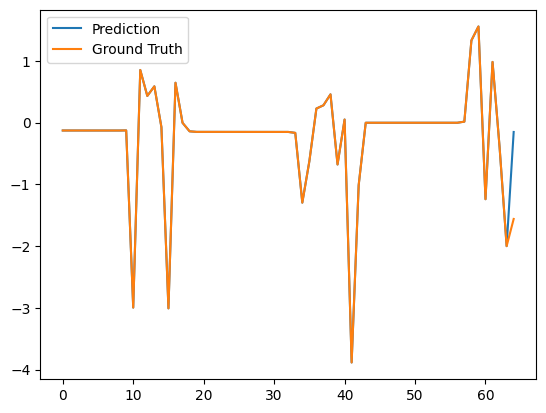

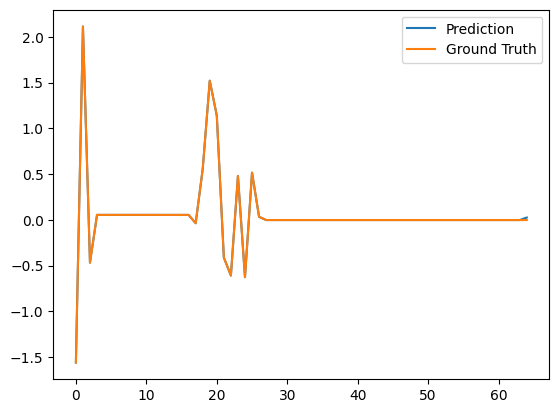

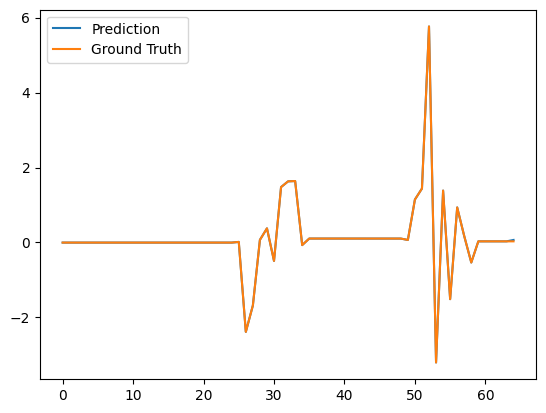

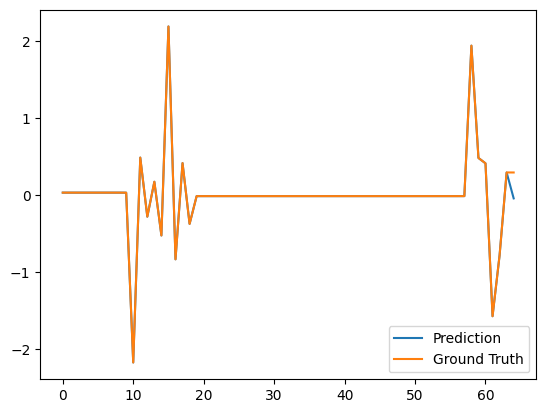

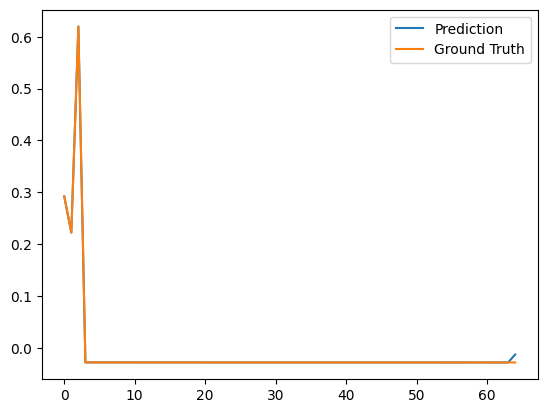

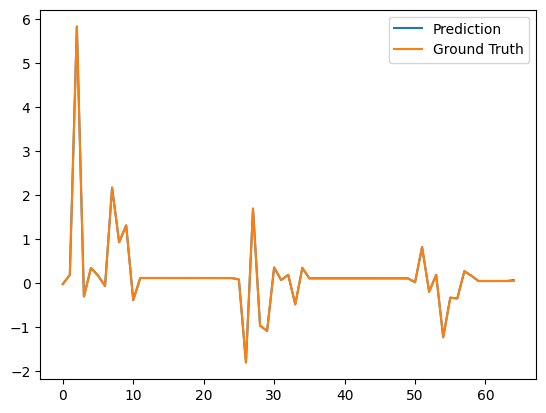

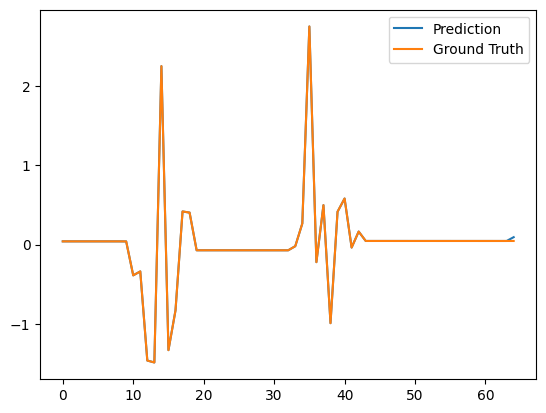

KeyboardInterrupt: 

In [31]:
import time

model_test = PatchTSTForPrediction.from_pretrained('model/checkpoint-15864')

test_args = TrainingArguments(
    output_dir='results'
)

trainer = Trainer(
    model=model_test,
    args=test_args,
)

test_dataset = TimeSeriesForecastDataset(
    test_data, test_mask, seq_len, pred_len)
# predction_output = trainer.predict(test_dataset)
# predction_output.predictions

for i in range(0, len(test_data) - seq_len - pred_len + 1, seq_len):
  sample = test_data[i:i+seq_len]
  with torch.no_grad():
    prediction = model_test(
        past_values=torch.Tensor(test_data[i:i+seq_len]).unsqueeze(0),
        past_observed_mask=torch.Tensor(test_mask[i:i+seq_len])
    ).prediction_outputs.squeeze(0).squeeze(0).numpy()
    
    prediction = np.append(test_data[i:i+seq_len+pred_len-1, 11], prediction[11])

    plt.plot(prediction, label='Prediction')
    plt.plot(test_data[i:i+seq_len+pred_len, 11], label='Ground Truth')
    plt.legend()
    plt.show()
    time.sleep(2)
    plt.close()

test_data[seq_len:seq_len+pred_len, 11], prediction[11]